# FEES y cinco alternativas: protección anticíclica en CLP

Referencia: FEES histórico observado. H1 más letras, H2 puts de 12 meses, H3 Treasury corto, H4 más MBS. H5 asigna presupuesto entre esas cinco estrategias, con una búsqueda de pesos que prioriza el peor trimestre de contracción del PIB en CLP real.

Los datos oficiales están entregados. No se consultan APIs de precios al analizar. La primera celda encuentra el proyecto local, acepta entrega_fees.zip subido al runtime o descarga el archivo público de GitHub. No se necesitan credenciales.

Las puts son modeladas y la evaluación usa PIB revisado con rezago conservador. Un mejor resultado de entrenamiento no garantiza protección futura ni certifica admisibilidad normativa.


In [1]:
from pathlib import Path
import io
import os
import zipfile
import requests

proyecto = Path.cwd()
if not (proyecto / "config.json").exists() and (proyecto.parent / "config.json").exists():
    proyecto = proyecto.parent
if not (proyecto / "config.json").exists():
    archivo = proyecto / "entrega_fees.zip"
    if archivo.exists():
        contenido = archivo.read_bytes()
    else:
        url = "https://github.com/eldiegoveliz/presentacionasset/archive/refs/heads/analisis-fees.zip"
        respuesta = requests.get(url, timeout=60)
        respuesta.raise_for_status()
        contenido = respuesta.content
    destino = proyecto / "proyecto_fees"
    with zipfile.ZipFile(io.BytesIO(contenido)) as z:
        z.extractall(destino)
    proyecto = next(destino.rglob("config.json")).parent
os.chdir(proyecto)
print("Archivos de trabajo:", proyecto)


Archivos de trabajo: /tmp/fees-notebook-qbdhmszs/proyecto


In [2]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


## Código visible de carteras.py

In [3]:
"""Motores de carteras: rebalanceo anual y puts con vencimiento fijo."""
from math import erf, exp, log, sqrt

import numpy as np
import pandas as pd



### precio_put_black76

Prima europea teórica. Al vencer queda el valor intrínseco, no se renueva mensualmente.

In [4]:
def precio_put_black76(futuro, strike, volatilidad, tasa, plazo):
    if futuro <= 0 or strike <= 0 or volatilidad < 0 or plazo < 0:
        raise ValueError("Parámetros inválidos para la put")
    if plazo == 0:
        return max(strike - futuro, 0)
    if volatilidad == 0:
        return exp(-tasa * plazo) * max(strike - futuro, 0)
    d1 = (log(futuro / strike) + 0.5 * volatilidad ** 2 * plazo) / (volatilidad * sqrt(plazo))
    d2 = d1 - volatilidad * sqrt(plazo)
    n1 = 0.5 * (1 + erf(-d1 / sqrt(2)))
    n2 = 0.5 * (1 + erf(-d2 / sqrt(2)))
    return exp(-tasa * plazo) * (strike * n2 - futuro * n1)

### cartera_anual

Presupuesto completo: rebalancear en enero y dejar fluctuar los pesos durante el año.

In [5]:
def cartera_anual(retornos, pesos, costo=0.0005):
    """Objetivo en enero; los pesos fluctúan entre rebalanceos."""
    w = pd.Series(pesos, dtype=float).reindex(retornos.columns, fill_value=0)
    if (w < 0).any() or not np.isclose(w.sum(), 1) or retornos.isna().any().any():
        raise ValueError("Pesos o retornos inválidos")
    actuales = w.copy()
    rendimientos, auditoria = [], []
    for i, (fecha, r) in enumerate(retornos.iterrows()):
        rebalanceo = i == 0 or fecha.month == 1
        volumen = 1. if i == 0 else (w - actuales).abs().sum() if rebalanceo else 0.
        if rebalanceo:
            actuales = w.copy()
        bruto = actuales.dot(r)
        rendimientos.append((1 - costo * volumen) * (1 + bruto) - 1)
        auditoria.append({"fecha": fecha, "rebalanceo": rebalanceo, "costo": costo * volumen, **actuales.to_dict()})
        actuales = actuales * (1 + r) / (1 + bruto)
    return pd.Series(rendimientos, index=retornos.index), pd.DataFrame(auditoria).set_index("fecha")

### put_larga

Pagar una opción desde el FEES, mantener strike y cantidad, valorar su plazo residual y renovar al vencer.

In [6]:
def put_larga(fees, cobre, volatilidad, tasa, parametros, costo=0.0005):
    """Un contrato sintético de 6/12 meses; strike y cantidad fijos hasta vencer.

    El cobre continuo se usa como proxy de spot, NO como contrato histórico fijo.
    F(t,T)=proxy(t)*exp(r*(T-t)), con almacenaje menos conveniencia supuesto cero.
    Se pagan prima y costos vendiendo parte del FEES; no se toma deuda.
    """
    plazo = parametros["plazo_meses"]
    if plazo not in (6, 12) or not 0 <= parametros["nocional"] <= 1:
        raise ValueError("Plazo o nocional inválido")
    core, valor_opcion, riqueza_anterior = 1., 0., 1.
    cantidad, strike, sigma, entrada = 0., 0., 0., None
    resultados, auditoria = [], []
    for i, (fecha, retorno_fees) in enumerate(fees.items()):
        compra = i % plazo == 0
        prima, friccion, comision = 0., 0., 0.
        if compra:
            entrada = fecha - pd.offsets.MonthEnd(1)
            s0, sigma_hist, r0 = cobre.loc[entrada], volatilidad.loc[entrada], tasa.loc[entrada]
            if not np.isfinite([s0, sigma_hist, r0]).all() or s0 <= 0 or sigma_hist <= 0:
                raise ValueError(f"Faltan datos previos para comprar put: {entrada}")
            sigma = sigma_hist * parametros["multiplicador_vol"]
            f0 = s0 * exp(r0 * plazo / 12)
            strike = parametros["strike_relativo"] * f0
            cantidad = parametros["nocional"] * riqueza_anterior / f0
            prima = cantidad * precio_put_black76(f0, strike, sigma, r0, plazo / 12)
            friccion = prima * parametros["friccion_sobre_prima"]
            comision = costo * (prima + friccion)
            core = riqueza_anterior - prima - friccion - comision
            if core < 0:
                raise ValueError("Prima sin financiación: no se permite endeudamiento")
        restante = (plazo - (i % plazo) - 1) / 12
        s, r_actual = cobre.loc[fecha], tasa.loc[fecha]
        futuro_modelo = s * exp(r_actual * restante)
        precio = precio_put_black76(futuro_modelo, strike, sigma, r_actual, restante)
        valor_opcion = cantidad * precio
        core *= 1 + retorno_fees
        riqueza = core + valor_opcion
        resultados.append(riqueza / riqueza_anterior - 1)
        auditoria.append({"fecha": fecha, "compra": compra, "entrada": entrada,
                          "plazo_restante_meses": restante * 12, "strike_fijo": strike,
                          "cantidad_fija": cantidad, "vol_compra_fija": sigma,
                          "prima_por_riqueza_previa": prima / riqueza_anterior,
                          "friccion_por_riqueza_previa": friccion / riqueza_anterior,
                          "comision_por_riqueza_previa": comision / riqueza_anterior,
                          "valor_opcion": valor_opcion, "valor_FEES": core,
                          "pago_vencimiento": valor_opcion if restante == 0 else 0,
                          "riqueza": riqueza})
        riqueza_anterior = riqueza
    return pd.Series(resultados, index=fees.index), pd.DataFrame(auditoria).set_index("fecha")

### riqueza_y_caida

Acumular retornos e incluir el capital inicial al medir pérdidas.

In [7]:
def riqueza_y_caida(retornos):
    riqueza = (1 + retornos).cumprod()
    return riqueza, riqueza / riqueza.cummax().clip(lower=1) - 1

### metricas

Retorno compuesto y riesgo como contexto. El optimizador no maximiza CAGR.

In [8]:
def metricas(retornos):
    _, caida = riqueza_y_caida(retornos)
    return pd.DataFrame({"retorno_anual_pct": ((1 + retornos).prod() ** (12 / len(retornos)) - 1) * 100,
                         "volatilidad_anual_pct": retornos.std(ddof=1) * np.sqrt(12) * 100,
                         "caida_max_mensual_pct": caida.min() * 100,
                         "peor_mes_pct": retornos.min() * 100})

## Código visible de optimizacion.py

In [9]:
"""Búsqueda exhaustiva y explicable: pesos en rejilla, sin cortos ni deuda."""
from itertools import product

import numpy as np
import pandas as pd



### generar_pesos

Enumerar pesos en pasos de 5%, sin cortos ni deuda. Los límites son supuestos del experimento.

In [10]:
def generar_pesos(config):
    """Cinco estrategias; H2 (posición 2) limitada por riesgo de modelo."""
    n = round(1 / config["paso"])
    maximo = int(round(config["peso_max_estrategia"] * n))
    minimo_fees = int(round(config["peso_min_fees"] * n))
    max_put = int(round(config["peso_max_puts"] * n))
    candidatos = []
    for a, b, c, d in product(range(maximo+1), repeat=4):
        e = n - a - b - c - d
        if a >= minimo_fees and c <= max_put and 0 <= e <= maximo:
            candidatos.append([a/n, b/n, c/n, d/n, e/n])
    return np.asarray(candidatos)

### simular_mezclas

Calcular carteras candidatas con rebalanceo anual y costos, sin suponer pesos constantes cada mes.

In [11]:
def simular_mezclas(retornos, pesos, costo):
    """Simula todas las mezclas con pesos que fluctúan y rebalanceo en enero."""
    pesos = np.atleast_2d(pesos)
    actuales = pesos.copy()
    salida = np.empty((len(retornos), len(pesos)))
    for i, (fecha, r) in enumerate(retornos.iterrows()):
        if i == 0 or fecha.month == 1:
            volumen = np.ones(len(pesos)) if i == 0 else np.abs(actuales - pesos).sum(axis=1)
            actuales = pesos.copy()
        else:
            volumen = np.zeros(len(pesos))
        bruto = actuales @ r.to_numpy()
        salida[i] = (1 - costo * volumen) * (1 + bruto) - 1
        actuales = actuales * (1 + r.to_numpy()) / (1 + bruto[:, None])
    return pd.DataFrame(salida, index=retornos.index)

### elegir_pesos

Usar solo trimestres anteriores y PIB con 90 días de rezago. Maximizar el peor retorno en contracciones.

In [12]:
def elegir_pesos(trimestrales, crecimiento_pib, fecha_decision, config, candidatos):
    """PIB revisado con rezago conservador de 90 días; nunca usa trimestres posteriores."""
    conocidos = trimestrales.index + pd.Timedelta(days=config["rezago_pib_dias"]) <= pd.Timestamp(fecha_decision)
    conocidos &= crecimiento_pib.reindex(trimestrales.index).notna().to_numpy()
    malos = conocidos & (crecimiento_pib.reindex(trimestrales.index).to_numpy() < 0)
    if conocidos.sum() < config["min_trimestres"] or malos.sum() < config["min_contracciones"]:
        return None, None
    episodios = trimestrales.loc[malos].to_numpy()
    peor = episodios.min(axis=0)
    media = episodios.mean(axis=0)
    # Primero maximizar el peor trimestre de contracción. Desempatar por media
    # en contracciones y luego por menor concentración. No se usa CAGR total.
    orden = np.lexsort(((candidatos ** 2).sum(axis=1), -media, -peor))
    ranking = pd.DataFrame({"candidato": orden, "peor_contraccion_pct": peor[orden] * 100,
                            "media_contraccion_pct": media[orden] * 100,
                            "trimestres_conocidos": int(conocidos.sum()), "contracciones": int(malos.sum())})
    return int(orden[0]), ranking

### optimizar_progresivo

Elegir antes de cada año. La curva usa esos pesos históricos; los pesos finales no se aplican al pasado.

In [13]:
def optimizar_progresivo(retornos, factor_clp_real, crecimiento_pib, config):
    candidatos = generar_pesos(config)
    mezclas_usd = simular_mezclas(retornos, candidatos, config["costo_rebalanceo"])
    mezclas_real = (1 + mezclas_usd).mul(factor_clp_real, axis=0) - 1
    trimestrales = (1 + mezclas_real).resample("QE").prod() - 1
    conteos = mezclas_real.resample("QE").count().iloc[:, 0]
    trimestrales = trimestrales.loc[conteos == 3]
    calendario, auditoria = {}, []
    for anio in sorted(set(retornos.index.year)):
        fecha = pd.Timestamp(anio, 1, 1)
        elegido, ranking = elegir_pesos(trimestrales, crecimiento_pib, fecha, config, candidatos)
        if elegido is not None:
            calendario[anio] = candidatos[elegido]
            fila = dict(zip(retornos.columns, candidatos[elegido]))
            fila.update(fecha=fecha, ultimo_pib_permitido=fecha-pd.Timedelta(days=config["rezago_pib_dias"]),
                        ultimo_trimestre_usado=trimestrales.index[(trimestrales.index + pd.Timedelta(days=config["rezago_pib_dias"]) <= fecha) & crecimiento_pib.reindex(trimestrales.index).notna()].max(),
                        trimestres_conocidos=int(ranking.iloc[0].trimestres_conocidos),
                        peor_contraccion_entrenamiento_pct=ranking.iloc[0].peor_contraccion_pct,
                        contracciones=int(ranking.iloc[0].contracciones))
            auditoria.append(fila)
    if not calendario:
        raise ValueError("Historia insuficiente para evaluar la optimización temporal")
    inicio = pd.Timestamp(min(calendario), 1, 1)
    sub = retornos.loc[inicio:]
    actuales, resultado, registros = None, [], []
    for i, (fecha, r) in enumerate(sub.iterrows()):
        objetivo = calendario[fecha.year]
        rebal = i == 0 or fecha.month == 1
        volumen = 1. if i == 0 else np.abs(objetivo - actuales).sum() if rebal else 0.
        if rebal:
            actuales = objetivo.copy()
        bruto = actuales @ r.to_numpy()
        resultado.append((1 - config["costo_rebalanceo"] * volumen) * (1 + bruto) - 1)
        registros.append(dict(fecha=fecha, rebalanceo=rebal, **dict(zip(retornos.columns, actuales))))
        actuales = actuales * (1 + r.to_numpy()) / (1 + bruto)
    decision_final = retornos.index[-1] + pd.Timedelta(days=1)
    elegido, ranking = elegir_pesos(trimestrales, crecimiento_pib, decision_final, config, candidatos)
    pesos_finales = pd.Series(candidatos[elegido], index=retornos.columns)
    ranking = ranking.merge(pd.DataFrame(candidatos, columns=retornos.columns).reset_index(names="candidato"),
                            on="candidato", how="left", sort=False)
    # Sensibilidad: retirar una contracción cada vez y volver a elegir.
    sensibilidad = []
    malos_finales = crecimiento_pib.loc[crecimiento_pib < 0].index.intersection(trimestrales.index)
    for fecha in malos_finales:
        pib_sin_episodio = crecimiento_pib.drop(fecha)
        ix, _ = elegir_pesos(trimestrales, pib_sin_episodio, decision_final, config, candidatos)
        if ix is not None:
            sensibilidad.append(dict(episodio_excluido=fecha, **dict(zip(retornos.columns, candidatos[ix]))))
    return {"retornos_usd": pd.Series(resultado, index=sub.index, name="H5 Optimo temporal"),
            "pesos_finales": pesos_finales, "pesos_anuales": pd.DataFrame(auditoria).set_index("fecha"),
            "pesos_mensuales": pd.DataFrame(registros).set_index("fecha"), "ranking": ranking,
            "sensibilidad": pd.DataFrame(sensibilidad), "candidatos": len(candidatos),
            "casi_optimos_002pp": int((ranking.peor_contraccion_pct >= ranking.peor_contraccion_pct.iloc[0] - .02).sum())}

## Código visible de analisis.py

In [14]:
"""FEES observado, cuatro alternativas y una quinta mezcla anticíclica."""
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd()


### leer_config

Leer los supuestos guardados en config.json.

In [15]:
def leer_config():
    return json.loads((RAIZ / "config.json").read_text())

### cargar_datos

Unir FEES oficial, dólar diario BCCh, inflación, PIB y precios. No rellenar faltantes silenciosamente.

In [16]:
def cargar_datos(config):
    oficial = RAIZ / "data/oficial"
    fees = pd.read_csv(oficial / "fees_mensual.csv", index_col=0, parse_dates=True).retorno_usd
    fx = pd.read_csv(oficial / "bcch_dolar.csv", index_col=0, parse_dates=True).bcch_dolar
    ipc = pd.read_csv(oficial / "bcch_ipc.csv", index_col=0, parse_dates=True).bcch_ipc
    pib = pd.read_csv(oficial / "bcch_pib.csv", index_col=0, parse_dates=True).bcch_pib
    activos = {}
    for ticker in ("BIL", "SHY", "MBB"):
        d = pd.read_csv(RAIZ / f"data/raw/{ticker}.csv", index_col=0, parse_dates=True)
        activos[ticker] = d.ajustado.resample("ME").last().pct_change(fill_method=None)
    r = pd.DataFrame(dict(FEES=fees, **activos)).loc[fees.index]
    esperado = pd.date_range(config["inicio_analisis"], fees.index[-1], freq="ME")
    if r.isna().any().any() or not r.index.equals(esperado):
        raise ValueError("FEES y satélites sin calendario común completo")
    fx_m = fx.resample("ME").last()
    fechas_fx = pd.Series(fx.index, index=fx.index).resample("ME").last()
    if ((fechas_fx.index - pd.DatetimeIndex(fechas_fx)).days > 7).any():
        raise ValueError("Tipo de cambio mensual demasiado antiguo")
    factor_clp = (fx_m / fx_m.shift(1)).reindex(r.index)
    factor_real = factor_clp / (1 + ipc.reindex(r.index) / 100)
    if factor_real.isna().any():
        raise ValueError("No se permite interpolar inflación ni tipo de cambio")
    cobre = pd.read_csv(RAIZ / "data/raw/HG=F.csv", index_col=0, parse_dates=True).cierre.dropna().resample("ME").last()
    sigma = np.log(cobre / cobre.shift(1)).rolling(config["puts"]["ventana_vol_meses"]).std() * np.sqrt(12)
    tasas = {}
    for meses, serie in ((6, "DGS6MO"), (12, "DGS1")):
        tasas[meses] = pd.read_csv(RAIZ / f"data/raw/{serie}.csv", index_col=0, parse_dates=True)[serie].resample("ME").last() / 100
    return r, factor_clp, factor_real, pib.pct_change(fill_method=None), cobre, sigma, tasas

### evaluar_ciclo

Acumular retornos a trimestres completos y comparar contracciones del PIB.

In [17]:
def evaluar_ciclo(real, crecimiento_pib):
    trimestral = (1 + real).resample("QE").prod(min_count=3) - 1
    trimestral = trimestral.dropna(how="any")
    trimestral = trimestral.loc[trimestral.index.intersection(crecimiento_pib.dropna().index)]
    malos = crecimiento_pib.reindex(trimestral.index) < 0
    if malos.sum() == 0:
        raise ValueError("No hay contracciones para evaluar")
    resultado = pd.DataFrame({"media_contraccion_pct": trimestral.loc[malos].mean() * 100,
                              "peor_contraccion_pct": trimestral.loc[malos].min() * 100,
                              "trimestres_contraccion_con_perdida": (trimestral.loc[malos] < 0).sum(),
                              "media_expansion_pct": trimestral.loc[~malos].mean() * 100,
                              "correlacion_PIB": trimestral.corrwith(crecimiento_pib.reindex(trimestral.index))})
    resultado["contracciones_observadas"] = int(malos.sum())
    return resultado, trimestral

### bootstrap_ciclo

Intervalo descriptivo por bloques de cuatro trimestres, manteniendo fechas emparejadas.

In [18]:
def bootstrap_ciclo(trimestral, crecimiento_pib, semilla=20261108):
    delta = trimestral.iloc[:, -1] - trimestral.iloc[:, 0]
    datos = np.column_stack([delta, crecimiento_pib.reindex(trimestral.index)])
    rng = np.random.default_rng(semilla)
    estimaciones = []
    for _ in range(2000):
        inicios = rng.integers(0, len(datos), size=int(np.ceil(len(datos) / 4)))
        ix = ((inicios[:, None] + np.arange(4)) % len(datos)).ravel()[:len(datos)]
        muestra = datos[ix]
        contraccion = muestra[:, 1] < 0
        if contraccion.any():
            estimaciones.append(muestra[contraccion, 0].mean() * 100)
    return pd.Series({"diferencia_media_contraccion_pp": delta.loc[crecimiento_pib.reindex(delta.index) < 0].mean() * 100,
                      "ic95_inferior_pp": np.quantile(estimaciones, 0.025),
                      "ic95_superior_pp": np.quantile(estimaciones, 0.975), "bloque_trimestres": 4})

### ejecutar

Construir H1–H4, estimar H5, evaluar protección, guardar auditorías y sensibilidades.

In [19]:
def ejecutar():
    config = leer_config()
    if [e["tipo"] for e in config["carteras"]] != ["referencia", "letras", "puts", "corto", "mbs"]:
        raise ValueError("La rejilla requiere el orden FEES, H1 letras, H2 puts, H3 corto, H4 MBS")
    salida = RAIZ / "results"
    figuras = salida / "figuras"
    figuras.mkdir(parents=True, exist_ok=True)
    r, factor_clp, factor_real, pib, cobre, sigma, tasas = cargar_datos(config)
    carteras, auditorias = {}, []
    for e in config["carteras"]:
        nombre = e["nombre"]
        if e["tipo"] == "referencia":
            carteras[nombre] = r.FEES.copy()
        elif e["tipo"] == "puts":
            carteras[nombre], puts = put_larga(r.FEES, cobre, sigma, tasas[12], config["puts"], config["costo_por_dolar_transado"])
        else:
            pesos = {"FEES": 1 - e["peso_satelite"], e["satelite"]: e["peso_satelite"]}
            carteras[nombre], audit = cartera_anual(r, pesos, config["costo_por_dolar_transado"])
            audit["cartera"] = nombre
            auditorias.append(audit)
    cinco = pd.DataFrame(carteras)
    opt = optimizar_progresivo(cinco, factor_real, pib, config["optimizacion"])
    cfg_prudente = dict(config["optimizacion"], peso_min_fees=.20, peso_max_estrategia=.60)
    prudente = optimizar_progresivo(cinco, factor_real, pib, cfg_prudente)
    prudente["pesos_finales"].rename("peso").to_csv(salida / "pesos_con_limites_prudentes.csv")
    seis = cinco.copy()
    seis["H5 Optimo temporal"] = opt["retornos_usd"]
    clp = (1 + seis).mul(factor_clp, axis=0) - 1
    real = (1 + seis).mul(factor_real, axis=0) - 1
    comparables = real.dropna(how="any")
    ciclo, trimestres = evaluar_ciclo(comparables, pib)
    general = metricas(comparables)
    incertidumbre = bootstrap_ciclo(trimestres, pib)
    opt["pesos_finales"].rename("peso").to_csv(salida / "pesos_optimos_finales.csv")
    opt["pesos_anuales"].to_csv(salida / "pesos_optimos_anuales.csv")
    opt["pesos_mensuales"].to_csv(salida / "pesos_optimos_mensuales.csv")
    opt["ranking"].head(30).to_csv(salida / "ranking_optimizacion.csv", index=False)
    opt["sensibilidad"].to_csv(salida / "sensibilidad_excluir_contraccion.csv", index=False)
    tablas = {"retornos_carteras_usd": seis, "retornos_carteras_clp": clp, "retornos_carteras_clp_real": real,
              "ciclo_contracciones": ciclo, "retornos_trimestrales_clp_real": trimestres,
              "metricas_clp_real": general, "puts_auditoria": puts,
              "rebalanceos_simulados": pd.concat(auditorias),
              "contexto_macro": pd.DataFrame({"variacion_PIB_real": pib}),
              "conversion_bcch": pd.DataFrame({"factor_USD_CLP": factor_clp, "factor_USD_CLP_real": factor_real})}
    for nombre, tabla in tablas.items():
        tabla.to_csv(salida / f"{nombre}.csv")
    incertidumbre.to_csv(salida / "incertidumbre_ciclo.csv", header=["valor"])
    # Exposición económica aproximada antes de pagar la prima, evitando contar
    # estrategias que comparten el FEES como si fueran cinco activos distintos.
    w = opt["pesos_finales"].to_numpy()
    exposicion = {"Nucleo FEES antes de prima": 0., "BIL": 0., "SHY": 0., "MBB": 0.}
    for peso, escenario in zip(w, config["carteras"]):
        satelite = escenario.get("peso_satelite", 0)
        exposicion["Nucleo FEES antes de prima"] += peso * (1 - satelite)
        if satelite:
            exposicion[escenario["satelite"]] += peso * satelite
    exposicion["Nocional put (no sumar a activos)"] = config["puts"]["nocional"] * w[2]
    exposicion = pd.Series(exposicion)
    exposicion.rename("fraccion_capital").to_csv(salida / "exposicion_optima.csv")
    sensibilidad = []
    for plazo in (6, 12):
        for multiplicador in (1., 1.25, 1.5):
            params = dict(config["puts"], plazo_meses=plazo, multiplicador_vol=multiplicador)
            serie, _ = put_larga(r.FEES, cobre, sigma, tasas[plazo], params, config["costo_por_dolar_transado"])
            otra = (1 + serie) * factor_real - 1
            met, _ = evaluar_ciclo(otra.to_frame("puts"), pib)
            sensibilidad.append(dict(plazo_meses=plazo, multiplicador_vol=multiplicador, **met.iloc[0].to_dict()))
    sensibilidad = pd.DataFrame(sensibilidad)
    sensibilidad.to_csv(salida / "sensibilidad_puts_largas.csv", index=False)
    # Menos MBS solo desde que el FEES efectivamente comenzó a invertir en ellos.
    # Es atribución marginal proxy, no retorno oficial de una cartera sin MBS.
    menos = r.FEES.copy()
    desde = menos.index >= pd.Timestamp("2023-12-31")
    menos.loc[desde] += .02 * (r.BIL - r.MBB).loc[desde]
    sin_mbs, _ = evaluar_ciclo(((1 + menos) * factor_real - 1).loc["2023-12":].to_frame("MBS -2 pp (atribucion proxy)"), pib)
    sin_mbs.to_csv(salida / "sensibilidad_menos_mbs.csv")
    graficos(seis, clp, real, pib, opt, puts)
    escribir_informe(config, ciclo, general, opt, exposicion, incertidumbre, sensibilidad, r, trimestres, prudente["pesos_finales"])
    print("Pesos finales, para uso posterior al cierre de la muestra:")
    print((opt["pesos_finales"] * 100).round(1).to_string())
    print("\nEvaluación temporal en contracciones, CLP real:")
    print(ciclo.round(3).to_string())
    return ciclo

### graficos

Separar rentabilidad sin flujos, saldo efectivo con flujos y rebalanceos simulados.

In [20]:
def graficos(usd, clp, real, pib, opt, puts):
    carpeta = RAIZ / "results/figuras"
    plt.rcParams.update({"figure.figsize": (11, 6), "axes.spines.top": False, "axes.spines.right": False,
                         "axes.grid": True, "grid.alpha": .2, "svg.fonttype": "none", "svg.hashsalt": "fees"})
    def guardar(nombre):
        plt.tight_layout(); plt.savefig(carpeta / f"{nombre}.png", dpi=150)
        if nombre in ("fees_historico", "pib_y_carteras"):
            archivo_svg = carpeta / f"{nombre}.svg"
            plt.savefig(archivo_svg, metadata={"Date": None})
            archivo_svg.write_text("\n".join(linea.rstrip() for linea in archivo_svg.read_text().splitlines()) + "\n")
        plt.close()
    riqueza, _ = riqueza_y_caida(clp.iloc[:, :1])
    origen = riqueza.index[0] - pd.offsets.MonthEnd(1)
    riqueza = pd.concat([pd.DataFrame(1., index=[origen], columns=riqueza.columns), riqueza])
    ax = (100 * riqueza).plot(title="FEES observado en CLP: gestión histórica incorporada")
    for fecha, texto in [("2021-09-27", "Fin gestión acciones"), ("2023-11-02", "Inicio MBS")]:
        ax.axvline(pd.Timestamp(fecha), linestyle="--", alpha=.6, color="gray")
        ax.text(pd.Timestamp(fecha), ax.get_ylim()[1], texto, rotation=90, va="top", fontsize=8)
    ax.set_ylabel("Índice de rentabilidad, base 100; sin aportes/retiros")
    guardar("fees_historico")
    riqueza, caida = riqueza_y_caida(real.dropna(how="any"))
    origen = riqueza.index[0] - pd.offsets.MonthEnd(1)
    riqueza = pd.concat([pd.DataFrame(1., index=[origen], columns=riqueza.columns), riqueza])
    ax = (100 * riqueza).plot(title="FEES, cuatro alternativas y H5 temporal, en CLP real")
    ax.set_ylabel("Poder adquisitivo por 100 iniciales; mismo inicio para las seis")
    guardar("riqueza_real")
    ax = (100 * caida).plot(title="Caídas desde máximos, CLP real")
    ax.set_ylabel("Caída mensual (%)"); guardar("caidas_reales")
    q = (1 + real.dropna(how="any")).resample("QE").prod(min_count=3) - 1
    q = q.dropna().reindex(pib.dropna().index).dropna()
    fig, axs = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    axs[0].bar(q.index, pib.reindex(q.index)*100, width=55, color=np.where(pib.reindex(q.index)<0,"#b34d3f","#477d91"))
    axs[0].set_ylabel("PIB real trimestral (%)")
    for nombre in q:
        axs[1].plot(q.index, q[nombre] * 100, label=nombre)
    axs[1].legend(fontsize=8)
    axs[1].set_ylabel("Retorno trimestral CLP real (%)")
    for fecha in q.index[pib.reindex(q.index)<0]:
        for ax in axs:
            ax.axvspan(fecha.to_period("Q").start_time, fecha, color="gray", alpha=.08)
    fig.suptitle("El ciclo chileno y los recursos del fondo")
    guardar("pib_y_carteras")
    malos = q.loc[pib.reindex(q.index)<0]
    ax = (malos*100).plot.bar(title="Solo trimestres de contracción del PIB", figsize=(12, 6))
    ax.set_xticks(np.arange(len(malos)), [str(x.to_period("Q")) for x in malos.index], rotation=40)
    ax.set_ylabel("Retorno CLP real (%)"); guardar("contracciones")
    campos = list(usd.columns[:5])
    ax = (opt["pesos_anuales"][campos]*100).plot.bar(stacked=True, title="H5: pesos elegidos antes de cada año")
    ax.set_xticks(np.arange(len(opt["pesos_anuales"])), [str(d.year) for d in opt["pesos_anuales"].index], rotation=0)
    ax.set_ylabel("% del presupuesto de estrategias"); guardar("pesos_h5")
    fig, axs = plt.subplots(2, 1, sharex=True)
    axs[0].plot(puts.index, puts.valor_opcion / puts.riqueza * 100)
    axs[0].set_ylabel("Valor de put / cartera (%)")
    compras = puts.loc[puts.compra]
    axs[1].bar(compras.index, compras.prima_por_riqueza_previa * 100, width=35)
    axs[1].set_ylabel("Prima al renovar (%)")
    for fecha in compras.index:
        axs[0].axvline(fecha, color="gray", linewidth=.4, alpha=.5)
    fig.suptitle("Puts de 12 meses: valor mensual y compras anuales (modelo)")
    guardar("puts_largas")
    # Calendario anual de rebalanceos de alternativas, sin atribuirlo al FEES real.
    registro = pd.read_csv(RAIZ / "results/rebalanceos_simulados.csv", index_col=0, parse_dates=True)
    h1 = registro.loc[registro.cartera == "H1 Mas letras"]
    ax = (h1[["FEES", "BIL"]]*100).plot(title="H1: pesos que fluctúan y vuelven al objetivo cada enero")
    for fecha in h1.index[h1.rebalanceo]:
        ax.axvline(fecha, linewidth=.4, alpha=.3, color="gray")
    ax.set_ylabel("Peso (%)"); guardar("rebalanceos")
    saldos = pd.read_csv(RAIZ / "data/oficial/fees_saldos.csv", index_col=0, parse_dates=True).iloc[:, 0]
    fx = pd.read_csv(RAIZ / "data/oficial/bcch_dolar.csv", index_col=0, parse_dates=True).iloc[:, 0].resample("ME").last()
    saldo_clp = saldos * fx.reindex(saldos.index) / 1000
    saldo_clp.rename("Saldo efectivo").to_csv(RAIZ / "results/saldo_efectivo_clp.csv", index_label="fecha")
    ax = saldo_clp.plot(title="Saldo efectivo del FEES en CLP: incluye aportes y retiros")
    ax.set_ylabel("Miles de millones de CLP corrientes")
    guardar("saldo_efectivo")

### escribir_informe

Generar el informe desde resultados, con límites de datos, valoración y política.

In [21]:
def escribir_informe(config, ciclo, general, opt, exposicion, incertidumbre, sensibilidad, r, trimestres, pesos_prudentes):
    final = opt["pesos_finales"].rename("peso_pct") * 100
    h5 = ciclo.loc["H5 Optimo temporal"]
    resumen = f"""# FEES y protección anticíclica en pesos

Se estudia si el fondo conserva poder adquisitivo en CLP durante contracciones chilenas. La quinta alternativa combina FEES observado y cuatro estrategias. Es un óptimo condicionado al objetivo, a una rejilla de pesos de 5% y a los supuestos del modelo; no una garantía de mejor comportamiento futuro.

## Datos y referencia completa

Retornos oficiales del FEES: {r.index[0].date()} a {r.index[-1].date()}, {len(r)} meses, extraídos de informes oficiales. El FEES histórico incorpora sus políticas, operaciones y rebalanceos efectivos. No es la antigua proxy de 69%. Se convierte con dólar observado diario BCCh tomado al último día disponible de cada mes y se deflacta con IPC mensual publicado por BCCh, fuente INE. El PIB es real trimestral desestacionalizado; se evalúa hasta {trimestres.index[-1].date()}, último trimestre común publicado.

Los retornos USD están redondeados a 0,01 puntos porcentuales en los PDF. No se usa la variación del saldo del fondo como retorno ni se imputa un retorno diario inexistente. El dólar observado corresponde a transacciones del día hábil anterior; no coincide necesariamente con el cierre FX usado por Hacienda. Por eso esta conversión CLP puede diferir del retorno CLP oficial.

![FEES observado](figuras/fees_historico.png)

Las líneas señalan fin de gestión de acciones (27/9/2021) e inicio de MBS (2/11/2023), documentados en informes; no son un calendario exhaustivo de todos los rebalanceos reales. No se inventaron fechas operativas. El FEES histórico incluía acciones antes de 2021.

## Las cuatro alternativas sobre el 100% del presupuesto

| Estrategia | Regla fijada antes de la comparación actual |
| --- | --- |
| H1 Más letras | 90% FEES observado + 10% BIL |
| H2 Puts largas | FEES observado, vendiendo parte para pagar put de 12 meses y sus costos; nocional 10%, strike 95% del futuro sintético inicial |
| H3 Treasury corto | 80% FEES observado + 20% SHY (Treasury 1–3 años) |
| H4 Más MBS | 90% FEES observado + 10% MBB; también se conserva una sensibilidad de reducción MBS desde su introducción |

Este diseño de núcleo y satélites reemplaza los cambios sobre la antigua cartera parcial. Los pesos técnicos son propuestas del asistente. H4 prueba mayor exposición; la reducción adicional de 2 pp desde diciembre de 2023 está en `sensibilidad_menos_mbs.csv`, rotulada como atribución marginal proxy, no cartera observada.

H1, H3 y H4 rebalancean en enero; entre fechas los pesos fluctúan. Sus costos son 5 pb por dólar comprado o vendido, incluida compra inicial. FEES observado ya es neto de sus comisiones. H5 tiene una capa adicional de 5 pb sobre el volumen de reasignación entre estrategias. No se confunde valoración mensual con rebalanceo mensual.

![Pesos y rebalanceos](figuras/rebalanceos.png)

## Quinta alternativa: objetivo y pesos

Se enumeraron {opt['candidatos']} combinaciones de cinco presupuestos. Los pesos suman uno, no hay cortos ni endeudamiento. Se permite 0%–100% en las estrategias sin puts y hasta 25% en H2 por incertidumbre de valoración. No se exige invertir en todas ni se fuerza una diversificación aparente: las estrategias comparten FEES. El tope de H2 es un supuesto del experimento, no una regla legal.

Objetivo: **maximizar el peor retorno trimestral en CLP real entre trimestres con caída del PIB real**. Se desempata por mayor media en contracciones y después menor concentración. El retorno total no entra en la función objetivo. Se exige un mínimo de 20 trimestres y tres contracciones conocidas para ajustar pesos.

Pesos finales estimados después del cierre de {r.index[-1].date()}, para decisiones posteriores. **No se aplican retrospectivamente para fabricar la curva de H5.**

{final.round(1).to_markdown()}

Como sensibilidad se impone un mínimo de 20% en FEES explícito y máximo de 60% por estrategia, manteniendo el tope H2 de 25%. Estos límites adicionales cambian el problema y pueden generar una mezcla distinta; no se presentan como restricciones oficiales.

{(pesos_prudentes.rename('peso_pct') * 100).round(1).to_markdown()}

La gráfica H5 usa selección progresiva anual: en cada enero solo se consideran retornos anteriores y trimestres cuyo cierre más 90 días es anterior a la decisión. La evaluación empieza en {opt['retornos_usd'].index[0].date()}. El PIB es revisado, no una base de primeras publicaciones archivadas; el rezago evita usar trimestres futuros pero no elimina sesgo por revisiones. Las hipótesis se diseñaron con conocimiento de este pasado. Es evaluación temporal retrospectiva, no una prueba independiente en tiempo real.

![Pesos progresivos](figuras/pesos_h5.png)

Exposición antes de pagar prima, como fracción del presupuesto final. El nocional de opción no se suma a los activos; H2 paga su prima reduciendo el núcleo FEES. El núcleo a su vez conserva las exposiciones cambiantes del FEES histórico.

{exposicion.round(4).to_markdown()}

`sensibilidad_excluir_contraccion.csv` vuelve a elegir pesos retirando un trimestre adverso cada vez. `ranking_optimizacion.csv` muestra las 30 mejores mezclas. Si cambian mucho los pesos o las puntuaciones son muy parecidas, no se justifica tratar la solución como única o estable.

Hay {opt['casi_optimos_002pp']} candidatos a no más de 0,02 pp trimestrales del mejor peor-retorno de entrenamiento. Ese margen es una sensibilidad descriptiva, no otro criterio para escoger pesos. La precisión de los PDF y la alta superposición de estrategias impiden atribuir importancia económica a diferencias de pocas milésimas de punto porcentual.

## Comportamiento durante contracciones

La siguiente comparación usa el mismo período temporal para las seis carteras y solo trimestres completos con PIB publicado. Rentabilidades en CLP real, porcentajes trimestrales. La correlación con PIB se reporta como descripción; el objetivo no fuerza una correlación negativa.

{ciclo.round(3).to_markdown()}

En la evaluación temporal, H5 registra pérdidas en {int(h5.trimestres_contraccion_con_perdida)} de {int(h5.contracciones_observadas)} contracciones. Su retorno medio en contracciones es {h5.media_contraccion_pct:.3f}% y el peor es {h5.peor_contraccion_pct:.3f}%. Su correlación con el crecimiento del PIB es {h5.correlacion_PIB:.3f}. **No se demuestra un portafolio anticíclico que preserve capital en todas las contracciones.** La selección mejora el objetivo de entrenamiento bajo límites, pero su protección observada es limitada. Las estrategias comparten gran parte del núcleo y la exposición al tipo de cambio.

![PIB y carteras](figuras/pib_y_carteras.png)

![Contracciones](figuras/contracciones.png)

El bootstrap por bloques de cuatro trimestres, 2.000 repeticiones, estima la diferencia de retorno medio H5 menos FEES durante contracciones: {incertidumbre.diferencia_media_contraccion_pp:.3f} pp trimestrales; intervalo descriptivo del 95% [{incertidumbre.ic95_inferior_pp:.3f}, {incertidumbre.ic95_superior_pp:.3f}]. No reestima todo el proceso de selección, no incluye incertidumbre de primas y no corrige múltiples comparaciones. Hay pocos episodios adversos.

Como contexto, estas métricas mensuales usan el mismo período de evaluación y CLP real. No determinan la elección de pesos.

{general.round(3).to_markdown()}

![Riqueza real](figuras/riqueza_real.png)

![Caídas reales](figuras/caidas_reales.png)

El saldo efectivo es otra medida: incluye aportes y retiros que sirven para financiar al Fisco. Una caída de este saldo no se interpreta automáticamente como pérdida financiera. El nivel se convierte a CLP con el mismo tipo de cambio oficial.

![Saldo efectivo](figuras/saldo_efectivo.png)

## Puts de largo plazo

Se compra en enero, se mantiene strike y cantidad durante 12 meses y se valora mensualmente con el plazo restante. Al vencer se liquida en efectivo en el modelo y se renueva; la última opción no vencida conserva su valor de mercado teórico. La prima y fricción del 10% de la prima se financian vendiendo parte del FEES. Se incluye el retorno sacrificado de ese capital y no se cuenta el pago dos veces.

No se consiguieron primas ni una curva histórica por contratos COMEX identificados. Se utiliza HG=F como proxy de spot para construir un **futuro sintético con vencimiento fijo**: `F(t,T)=proxy(t)*exp(r*(T-t))`, suponiendo almacenaje menos conveniencia cero. El proxy continuo puede introducir efectos de cambio de contrato; no se afirma haber eliminado ese riesgo de base ni replicado una opción negociable. La volatilidad de compra usa 24 retornos mensuales previos, anualizados y multiplicados por 1,25; se mantiene fija para valorar ese contrato. Las tasas son DGS1 para 12 meses y DGS6MO para 6 meses. Black-76 es europeo; no modela ejercicio americano ni entrega de futuros.

![Puts largas](figuras/puts_largas.png)

La siguiente sensibilidad mantiene H2 separado de la optimización: plazos 6/12 meses y multiplicadores de volatilidad 1/1,25/1,5. No se escoge el mejor supuesto para volver a optimizar la historia.

{sensibilidad.round(3).to_markdown(index=False)}

## Admisibilidad y límites

El objetivo económico no certifica admisibilidad. Puts de cobre no figuran en los instrumentos elegibles consultados. Los satélites alteran asignación y composición; H5 hereda esas limitaciones. Las bandas MBS 13%–17% aparecen en el informe anual 2024, p.33, y 2023, p.32; la pauta enlazada como vigente de 2023 describe otro rebalanceo. Se documenta esa diferencia de fuentes, sin presumir autorizaciones. No hay certificación de TE ex ante, ejecutabilidad ni autorización para invertir en ETFs.

La protección de poder adquisitivo del fondo durante contracciones es una aproximación a su mandato. No se han modelado ingresos fiscales del cobre, necesidades de caja ni financiación de retiros concretos. La mejor mezcla de esta rejilla y muestra puede ser peor en una crisis distinta. El análisis se limita al FEES, conforme a la instrucción del usuario; no incluye FRP.

Fuentes: [Hacienda, informes FEES](https://www.hacienda.cl/areas-de-trabajo/finanzas-internacionales/fondos-soberanos/fondo-de-estabilizacion-economica-y-social/informes-mensuales), [BCCh dólar observado](https://si3.bcentral.cl/Bdemovil/BDE/Series/MOV_ID_TC1), [BCCh IPC mensual](https://si3.bcentral.cl/Bdemovil/BDE/Series/MOV_SC_PR1), [BCCh PIB real](https://si3.bcentral.cl/siete/ES/Siete/Cuadro/CAP_CCNN/MN_CCNN76/CCNN2018_P0_V2?idSerie=F032.PIB.FLU.R.CLP.EP18.Z.Z.1.T), Yahoo ETF y cobre, FRED DGS1/DGS6MO. Los textos extraídos, páginas, URLs y hashes están en data/oficial. Se detectó que el enlace Hacienda de julio 2016 devolvía junio; se utilizó el informe correcto de [DIPRES](https://www.dipres.gob.cl/598/articles-149467_doc_pdf.pdf).
"""
    (RAIZ / "results/informe.md").write_text(resumen)
    valores = final.round(1)
    filas = "".join(f'<div class="fila"><span>{n}</span><div class="pista"><i style="width:{v}%"></i></div><b>{v:.0f}%</b></div>' for n,v in valores.items())
    html = """<!doctype html><html lang="es"><meta charset="utf-8"><style>
body{margin:0;color:var(--foreground);font-family:var(--font-sans)}h3{font-size:17px;margin:0 0 10px}.nota{font-size:13px;color:var(--muted-foreground);line-height:1.5}
.fila{display:grid;grid-template-columns:170px minmax(0,1fr) 45px;gap:8px;align-items:center;height:40px;font-size:13px}.pista{height:20px;background:var(--secondary);border-radius:var(--radius)}.pista i{display:block;height:20px;background:var(--chart-1);border-radius:var(--radius)}b{text-align:right}
</style><body><h3>H5: pesos finales del experimento anticíclico</h3><p class="nota">Búsqueda en pasos de 5%; objetivo: mejorar el peor trimestre de contracción en CLP real. Pesos para uso posterior a la muestra.</p>""" + filas + '<p class="nota">Las estrategias comparten el núcleo FEES. Puts modeladas; resultado condicionado, sin certificación de cumplimiento ni garantía futura.</p></body></html>'
    graficas = []
    for nombre in ("fees_historico", "pib_y_carteras"):
        svg = (RAIZ / f"results/figuras/{nombre}.svg").read_text()
        graficas.append('<div class="grafica">' + svg[svg.index('<svg'):] + '</div>')
    html = html.replace('</style>', '.grafica{margin:12px 0}.grafica svg{display:block;width:100%;height:auto}</style>')
    html = html.replace('<body>', '<body>' + ''.join(graficas))
    (RAIZ / "results/resumen.html").write_text(html)

## Ejecutar y evaluar

Se muestra protección durante contracciones y después los gráficos; el retorno total es secundario.

In [22]:
ciclo = ejecutar()
display(ciclo.round(3))

Pesos finales, para uso posterior al cierre de la muestra:
FEES historico            0.0
H1 Mas letras           100.0
H2 Puts 12m (modelo)      0.0
H3 Treasury corto         0.0
H4 Mas MBS                0.0

Evaluación temporal en contracciones, CLP real:
                      media_contraccion_pct  peor_contraccion_pct  trimestres_contraccion_con_perdida  media_expansion_pct  correlacion_PIB  contracciones_observadas
FEES historico                       -4.096               -14.922                                   6                1.515            0.085                         8
H1 Mas letras                        -3.983               -14.478                                   6                1.546            0.085                         8
H2 Puts 12m (modelo)                 -4.460               -15.310                                   6                1.461            0.111                         8
H3 Treasury corto                    -4.021               -14.485             

,media_contraccion_pct,peor_contraccion_pct,trimestres_contraccion_con_perdida,media_expansion_pct,correlacion_PIB,contracciones_observadas
FEES historico,-4.096,-14.922,6,1.515,0.085,8
H1 Mas letras,-3.983,-14.478,6,1.546,0.085,8
H2 Puts 12m (modelo),-4.460,-15.310,6,1.461,0.111,8
H3 Treasury corto,-4.021,-14.485,6,1.577,0.088,8
H4 Mas MBS,-4.096,-14.918,6,1.521,0.087,8
H5 Optimo temporal,-4.028,-14.485,6,1.594,0.088,8


In [23]:
display(pd.read_csv(RAIZ / 'results/pesos_optimos_finales.csv', index_col=0))
display(pd.read_csv(RAIZ / 'results/exposicion_optima.csv', index_col=0))

,peso
FEES historico,0.0
H1 Mas letras,1.0
H2 Puts 12m (modelo),0.0
H3 Treasury corto,0.0
H4 Mas MBS,0.0


,fraccion_capital
Nucleo FEES antes de prima,0.9
BIL,0.1
SHY,0.0
MBB,0.0
Nocional put (no sumar a activos),0.0


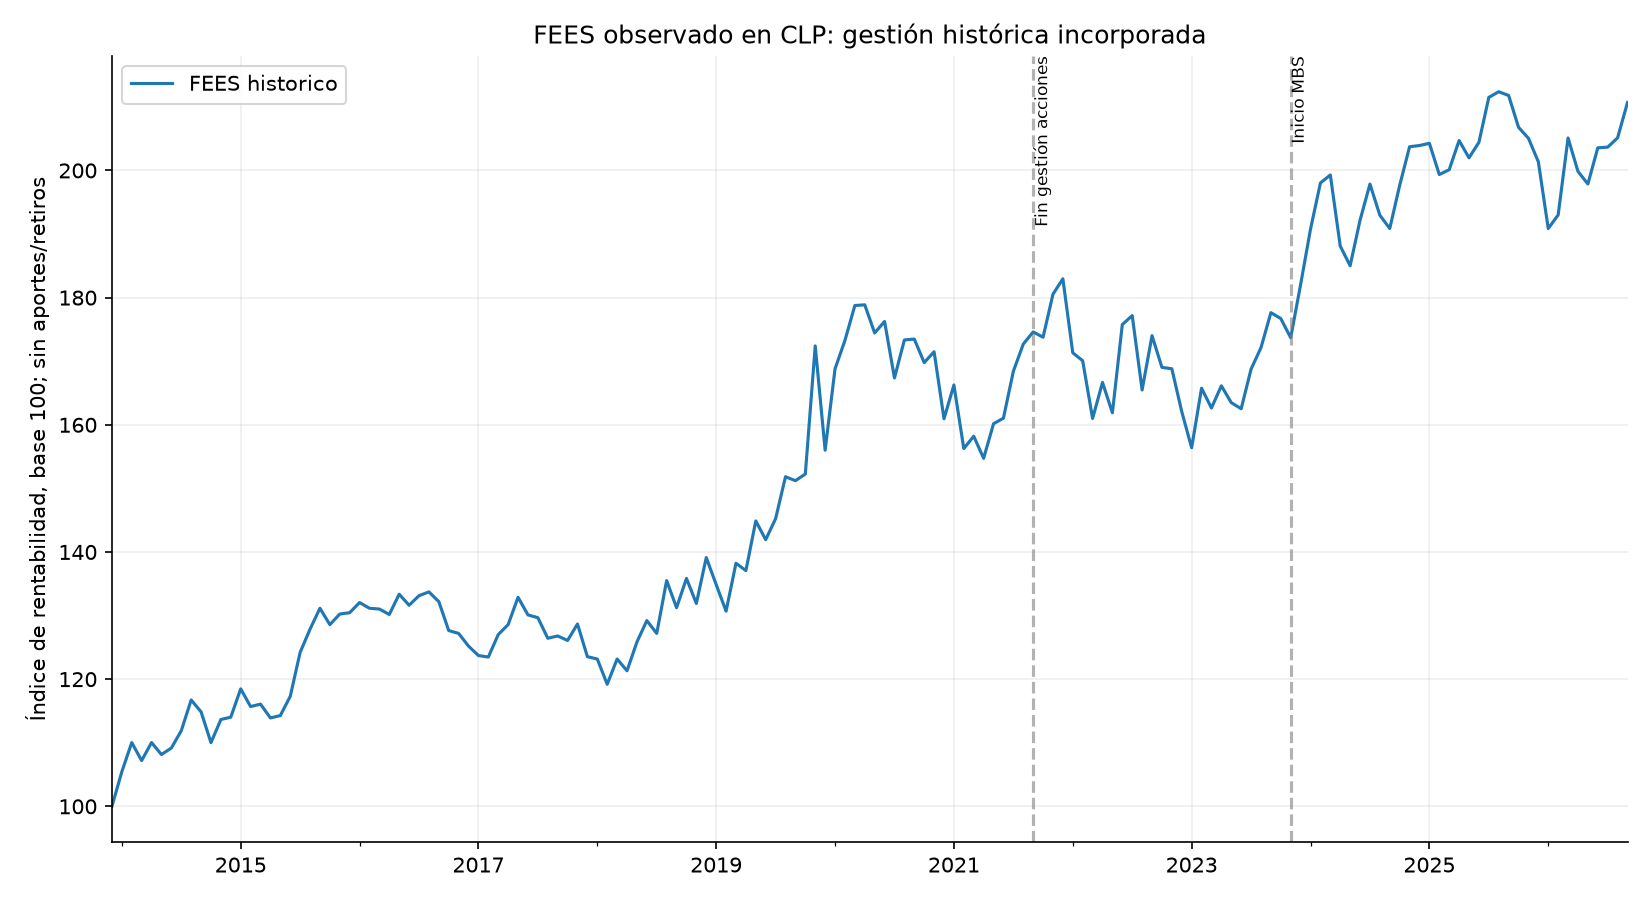

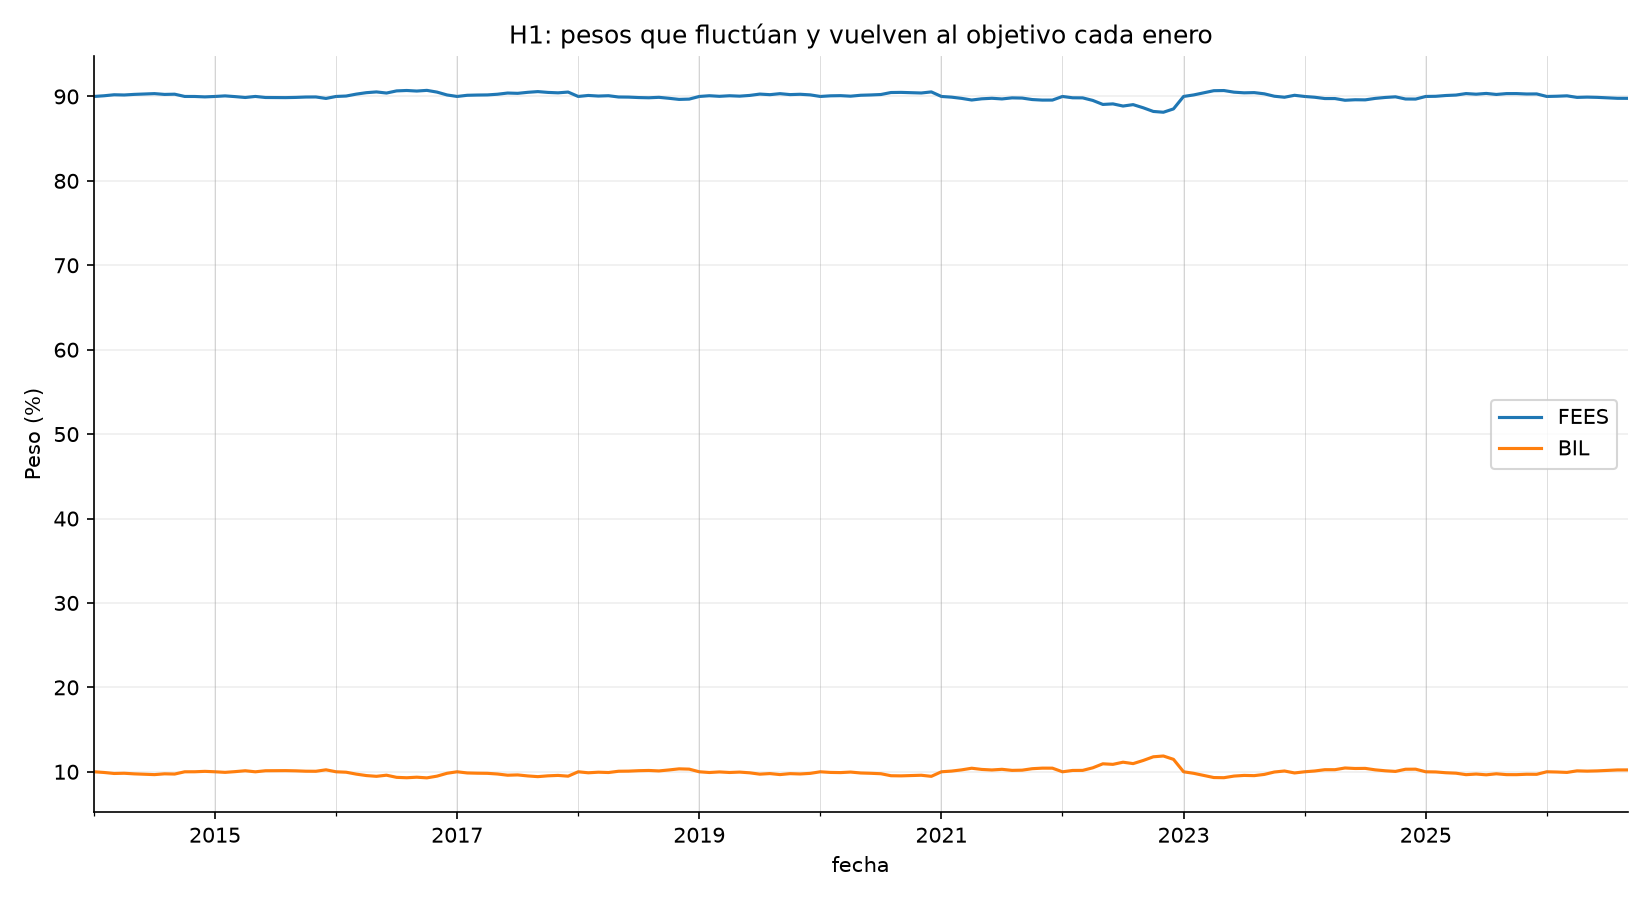

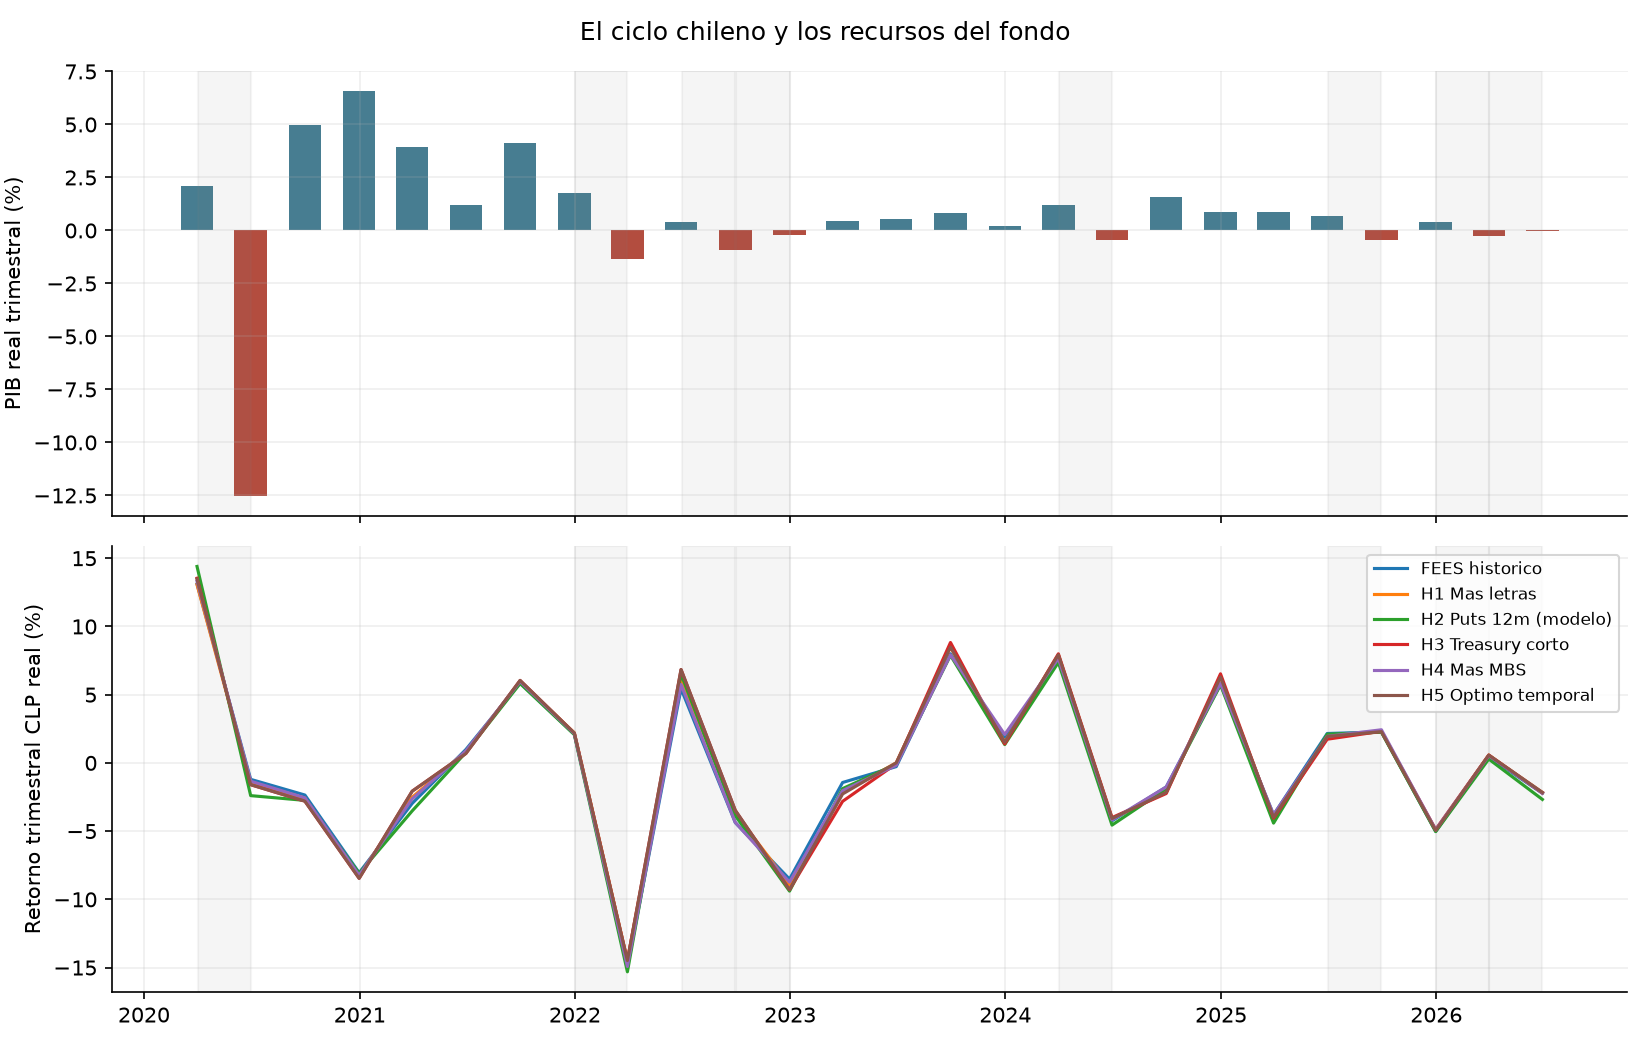

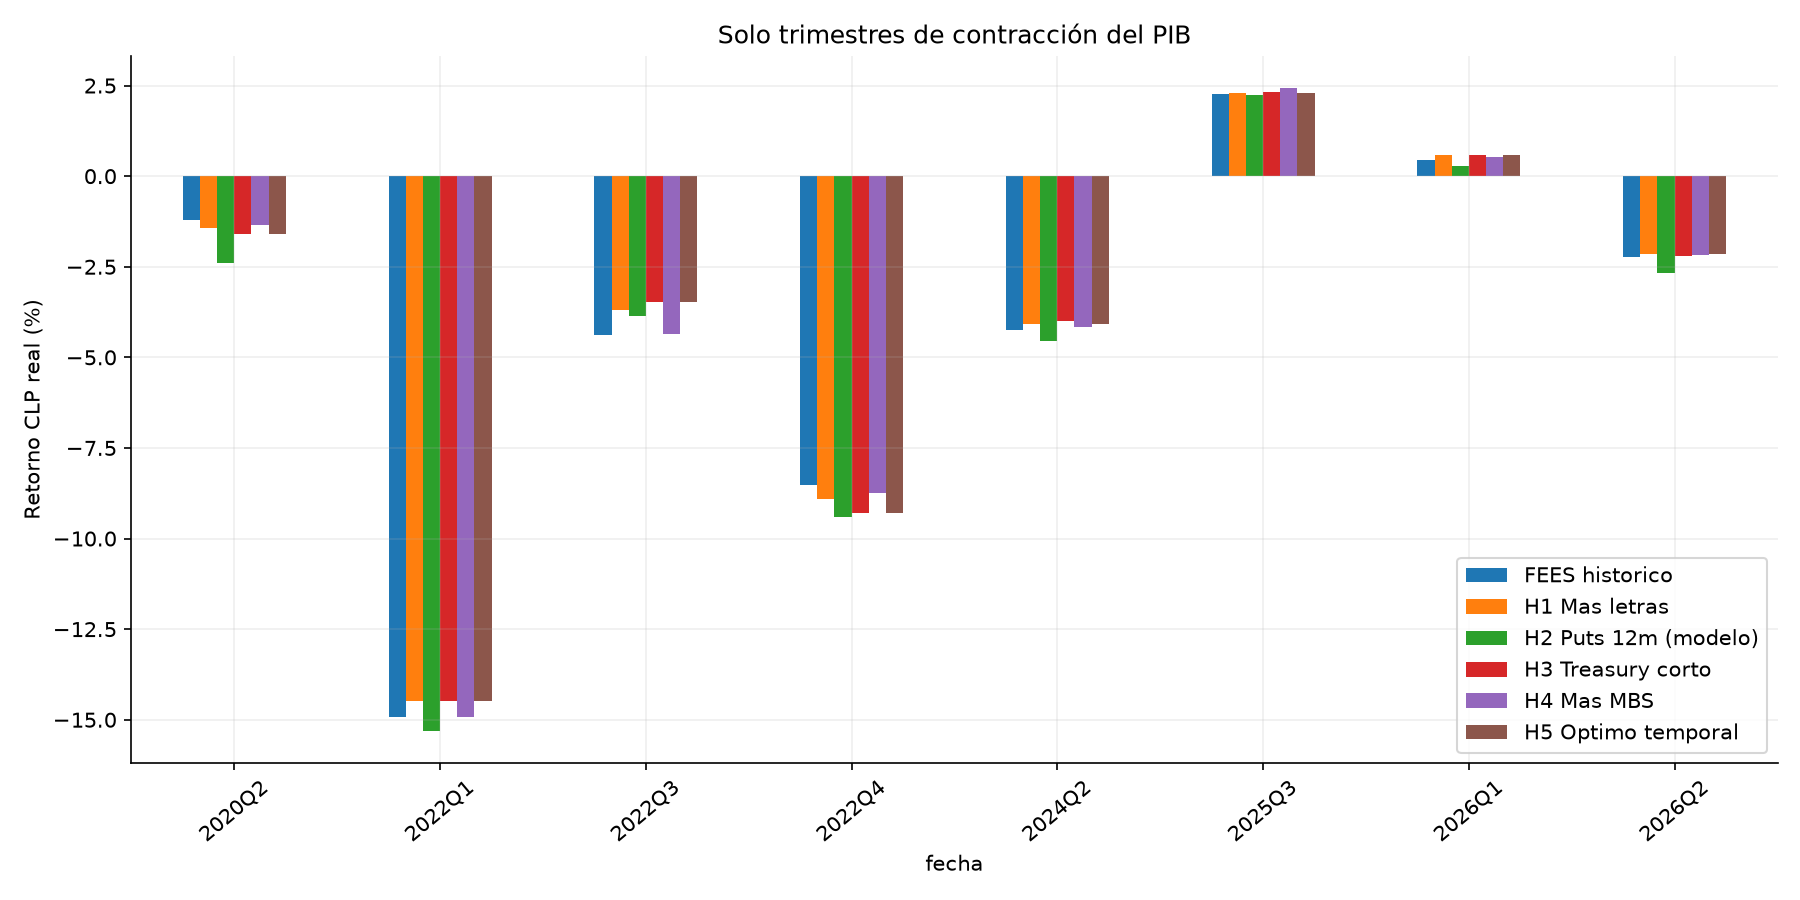

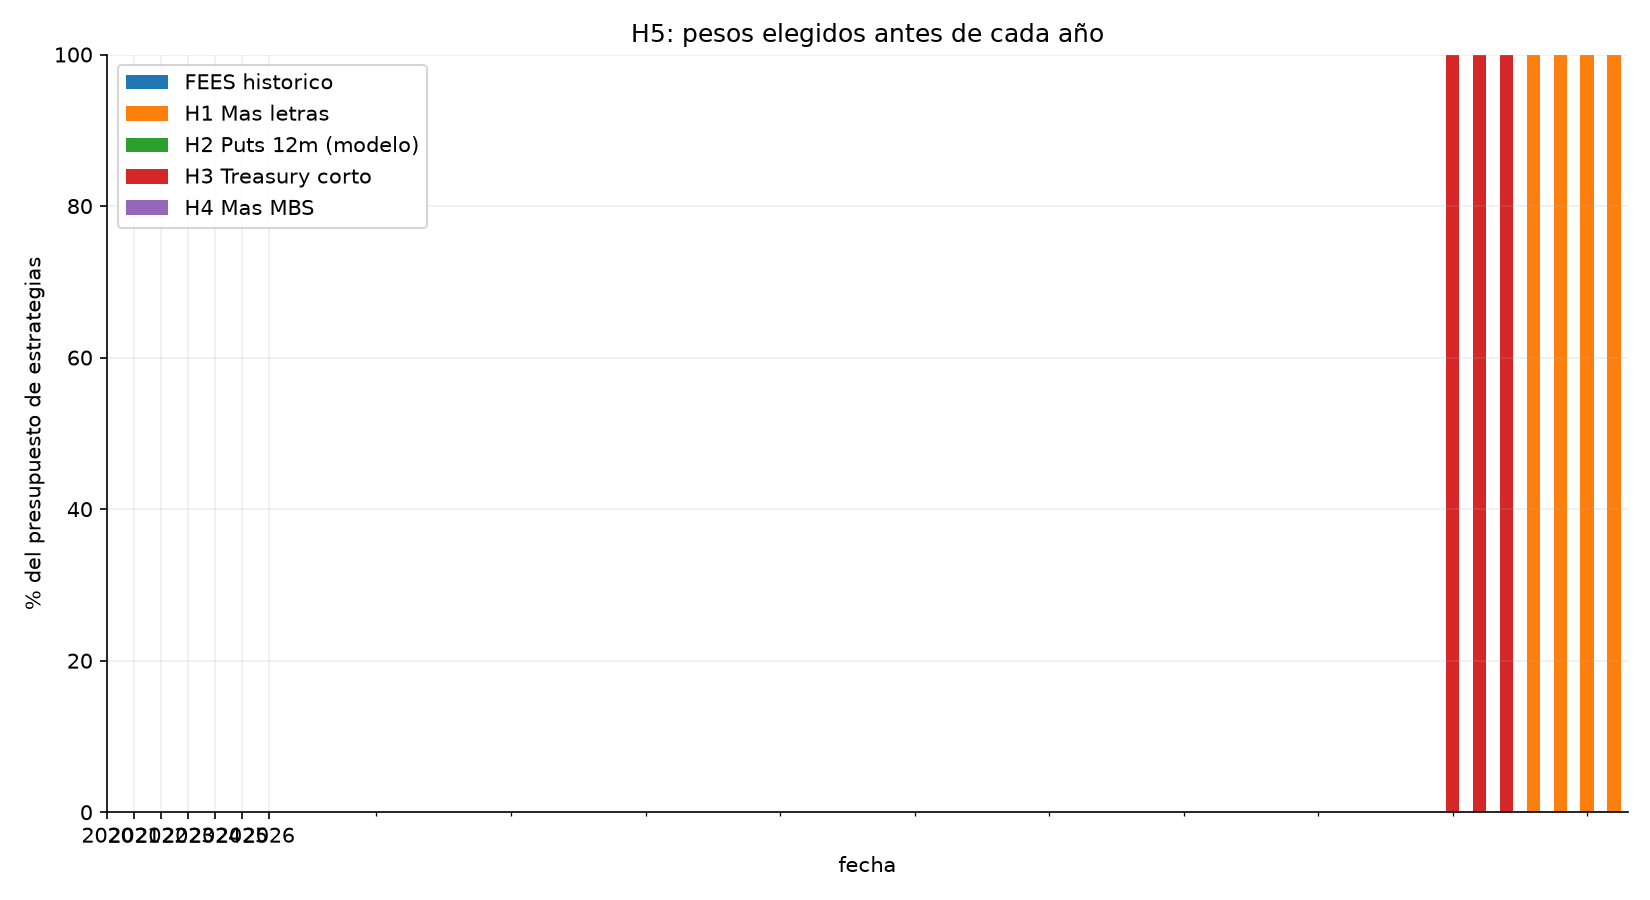

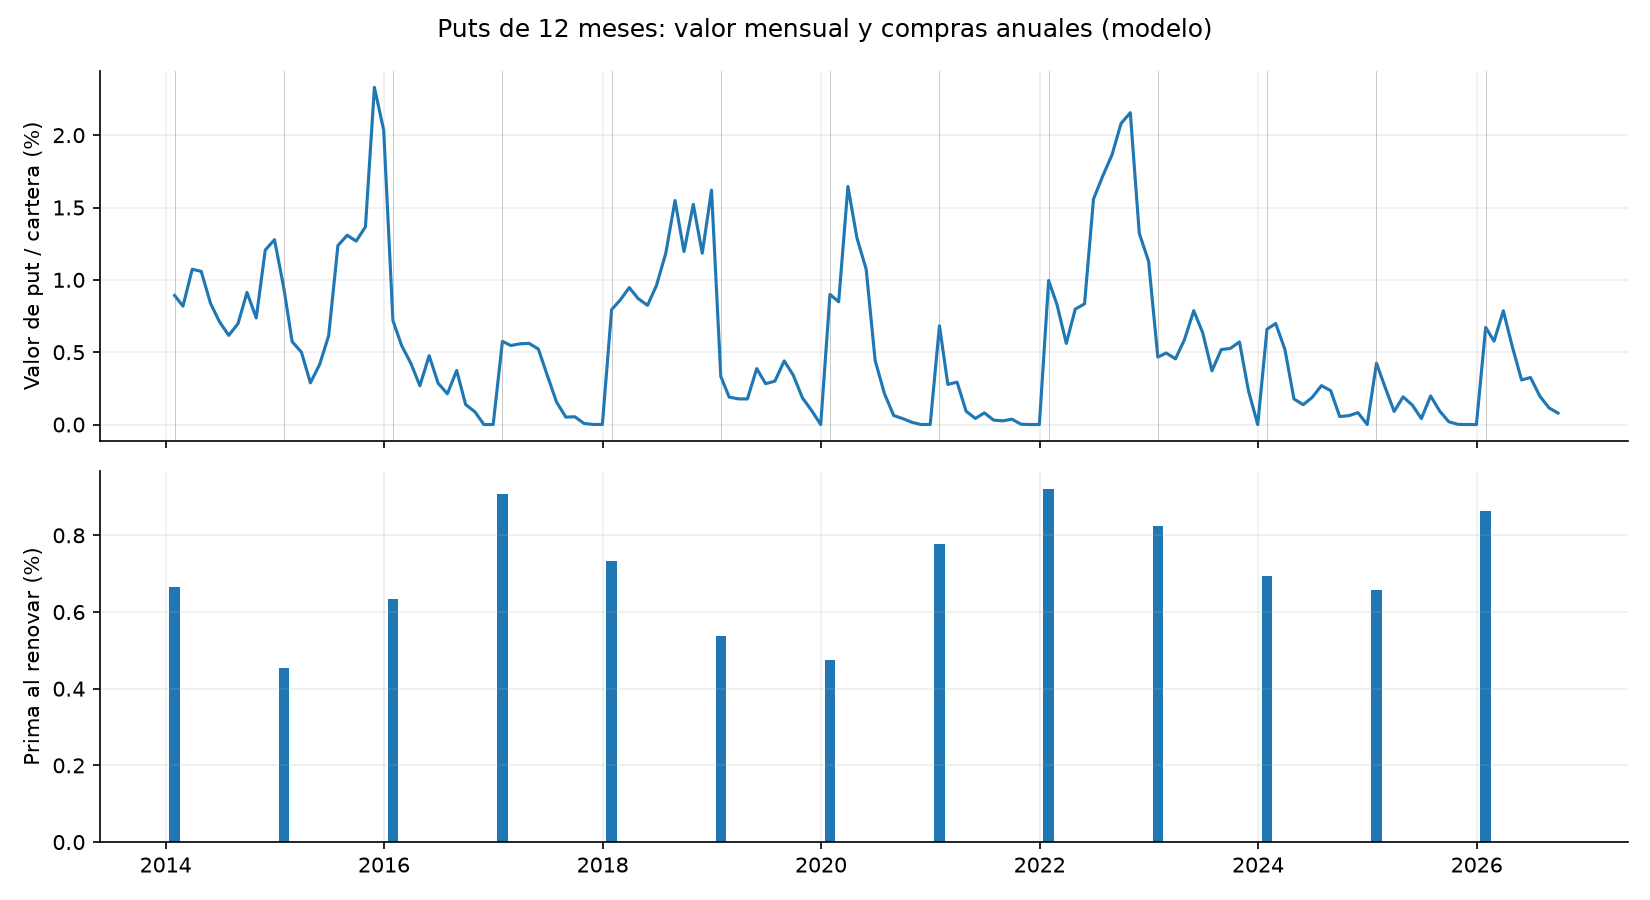

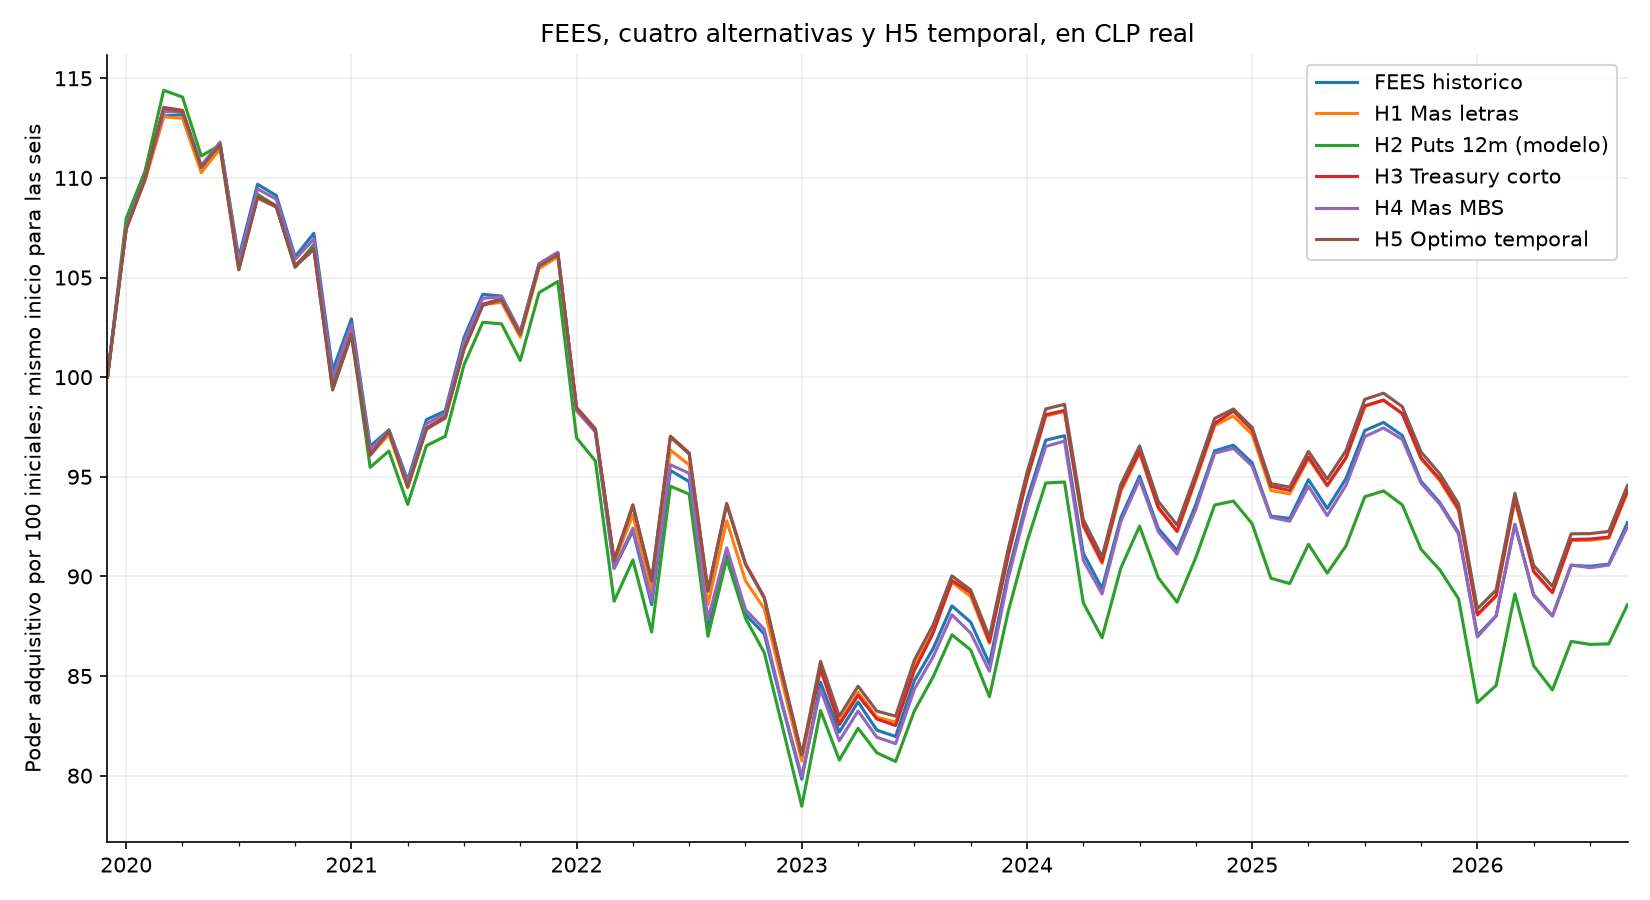

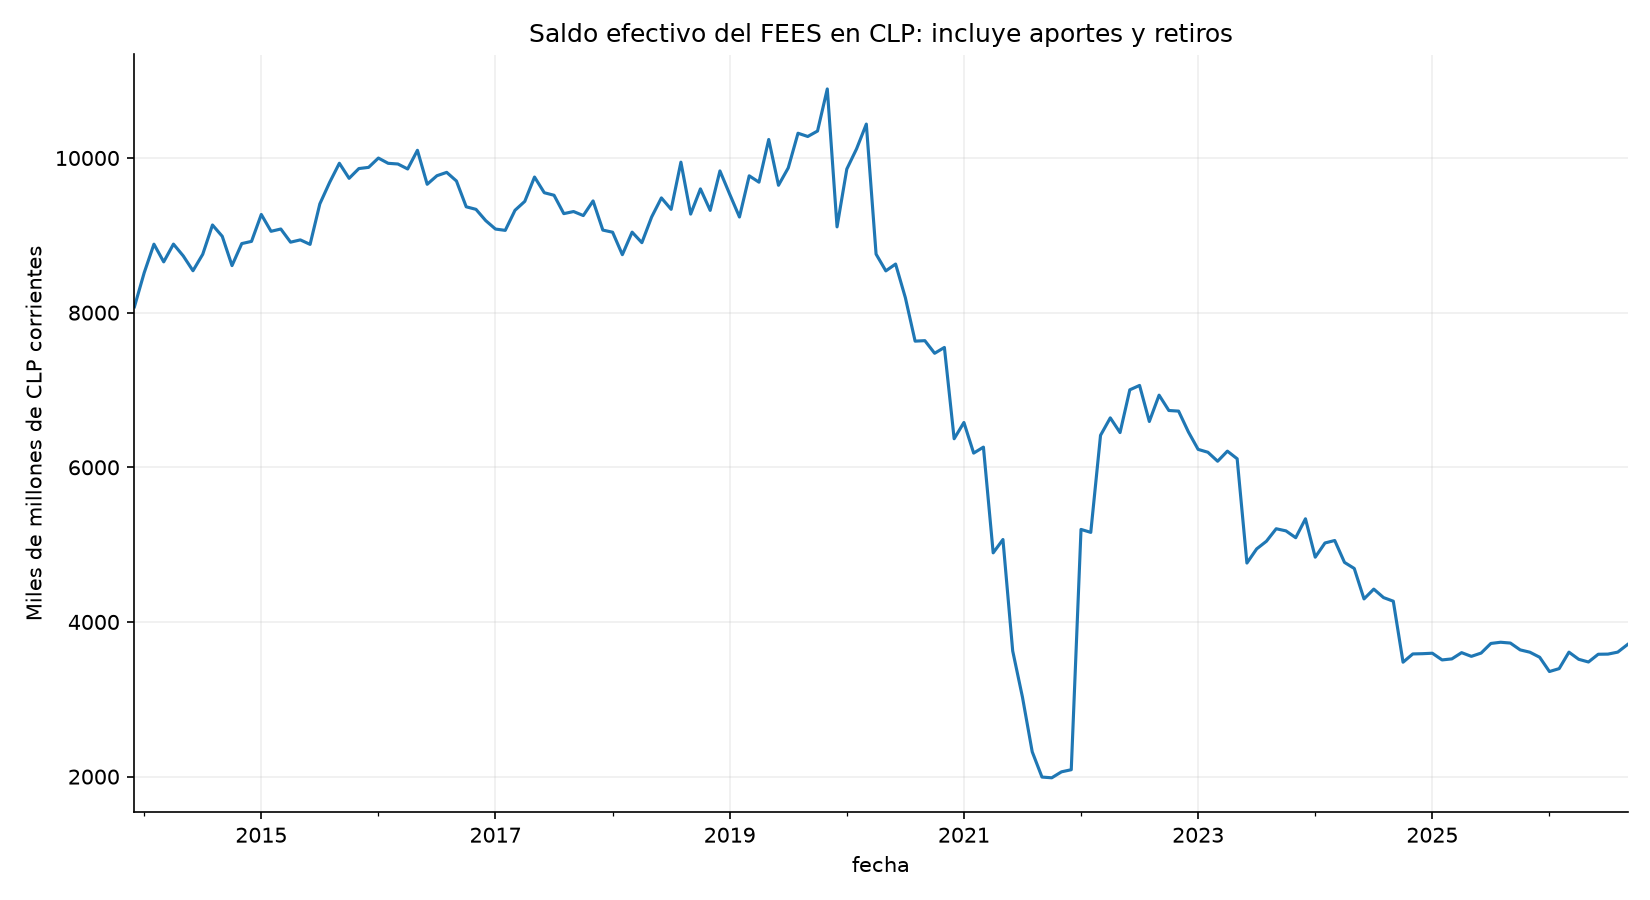

# FEES y protección anticíclica en pesos

Se estudia si el fondo conserva poder adquisitivo en CLP durante contracciones chilenas. La quinta alternativa combina FEES observado y cuatro estrategias. Es un óptimo condicionado al objetivo, a una rejilla de pesos de 5% y a los supuestos del modelo; no una garantía de mejor comportamiento futuro.

## Datos y referencia completa

Retornos oficiales del FEES: 2014-01-31 a 2026-09-30, 153 meses, extraídos de informes oficiales. El FEES histórico incorpora sus políticas, operaciones y rebalanceos efectivos. No es la antigua proxy de 69%. Se convierte con dólar observado diario BCCh tomado al último día disponible de cada mes y se deflacta con IPC mensual publicado por BCCh, fuente INE. El PIB es real trimestral desestacionalizado; se evalúa hasta 2026-06-30, último trimestre común publicado.

Los retornos USD están redondeados a 0,01 puntos porcentuales en los PDF. No se usa la variación del saldo del fondo como retorno ni se imputa un retorno diario inexistente. El dólar observado corresponde a transacciones del día hábil anterior; no coincide necesariamente con el cierre FX usado por Hacienda. Por eso esta conversión CLP puede diferir del retorno CLP oficial.

![FEES observado](figuras/fees_historico.png)

Las líneas señalan fin de gestión de acciones (27/9/2021) e inicio de MBS (2/11/2023), documentados en informes; no son un calendario exhaustivo de todos los rebalanceos reales. No se inventaron fechas operativas. El FEES histórico incluía acciones antes de 2021.

## Las cuatro alternativas sobre el 100% del presupuesto

| Estrategia | Regla fijada antes de la comparación actual |
| --- | --- |
| H1 Más letras | 90% FEES observado + 10% BIL |
| H2 Puts largas | FEES observado, vendiendo parte para pagar put de 12 meses y sus costos; nocional 10%, strike 95% del futuro sintético inicial |
| H3 Treasury corto | 80% FEES observado + 20% SHY (Treasury 1–3 años) |
| H4 Más MBS | 90% FEES observado + 10% MBB; también se conserva una sensibilidad de reducción MBS desde su introducción |

Este diseño de núcleo y satélites reemplaza los cambios sobre la antigua cartera parcial. Los pesos técnicos son propuestas del asistente. H4 prueba mayor exposición; la reducción adicional de 2 pp desde diciembre de 2023 está en `sensibilidad_menos_mbs.csv`, rotulada como atribución marginal proxy, no cartera observada.

H1, H3 y H4 rebalancean en enero; entre fechas los pesos fluctúan. Sus costos son 5 pb por dólar comprado o vendido, incluida compra inicial. FEES observado ya es neto de sus comisiones. H5 tiene una capa adicional de 5 pb sobre el volumen de reasignación entre estrategias. No se confunde valoración mensual con rebalanceo mensual.

![Pesos y rebalanceos](figuras/rebalanceos.png)

## Quinta alternativa: objetivo y pesos

Se enumeraron 7566 combinaciones de cinco presupuestos. Los pesos suman uno, no hay cortos ni endeudamiento. Se permite 0%–100% en las estrategias sin puts y hasta 25% en H2 por incertidumbre de valoración. No se exige invertir en todas ni se fuerza una diversificación aparente: las estrategias comparten FEES. El tope de H2 es un supuesto del experimento, no una regla legal.

Objetivo: **maximizar el peor retorno trimestral en CLP real entre trimestres con caída del PIB real**. Se desempata por mayor media en contracciones y después menor concentración. El retorno total no entra en la función objetivo. Se exige un mínimo de 20 trimestres y tres contracciones conocidas para ajustar pesos.

Pesos finales estimados después del cierre de 2026-09-30, para decisiones posteriores. **No se aplican retrospectivamente para fabricar la curva de H5.**

|                      |   peso_pct |
|:---------------------|-----------:|
| FEES historico       |          0 |
| H1 Mas letras        |        100 |
| H2 Puts 12m (modelo) |          0 |
| H3 Treasury corto    |          0 |
| H4 Mas MBS           |          0 |

Como sensibilidad se impone un mínimo de 20% en FEES explícito y máximo de 60% por estrategia, manteniendo el tope H2 de 25%. Estos límites adicionales cambian el problema y pueden generar una mezcla distinta; no se presentan como restricciones oficiales.

|                      |   peso_pct |
|:---------------------|-----------:|
| FEES historico       |         20 |
| H1 Mas letras        |         60 |
| H2 Puts 12m (modelo) |          0 |
| H3 Treasury corto    |         20 |
| H4 Mas MBS           |          0 |

La gráfica H5 usa selección progresiva anual: en cada enero solo se consideran retornos anteriores y trimestres cuyo cierre más 90 días es anterior a la decisión. La evaluación empieza en 2020-01-31. El PIB es revisado, no una base de primeras publicaciones archivadas; el rezago evita usar trimestres futuros pero no elimina sesgo por revisiones. Las hipótesis se diseñaron con conocimiento de este pasado. Es evaluación temporal retrospectiva, no una prueba independiente en tiempo real.

![Pesos progresivos](figuras/pesos_h5.png)

Exposición antes de pagar prima, como fracción del presupuesto final. El nocional de opción no se suma a los activos; H2 paga su prima reduciendo el núcleo FEES. El núcleo a su vez conserva las exposiciones cambiantes del FEES histórico.

|                                   |   0 |
|:----------------------------------|----:|
| Nucleo FEES antes de prima        | 0.9 |
| BIL                               | 0.1 |
| SHY                               | 0   |
| MBB                               | 0   |
| Nocional put (no sumar a activos) | 0   |

`sensibilidad_excluir_contraccion.csv` vuelve a elegir pesos retirando un trimestre adverso cada vez. `ranking_optimizacion.csv` muestra las 30 mejores mezclas. Si cambian mucho los pesos o las puntuaciones son muy parecidas, no se justifica tratar la solución como única o estable.

Hay 21 candidatos a no más de 0,02 pp trimestrales del mejor peor-retorno de entrenamiento. Ese margen es una sensibilidad descriptiva, no otro criterio para escoger pesos. La precisión de los PDF y la alta superposición de estrategias impiden atribuir importancia económica a diferencias de pocas milésimas de punto porcentual.

## Comportamiento durante contracciones

La siguiente comparación usa el mismo período temporal para las seis carteras y solo trimestres completos con PIB publicado. Rentabilidades en CLP real, porcentajes trimestrales. La correlación con PIB se reporta como descripción; el objetivo no fuerza una correlación negativa.

|                      |   media_contraccion_pct |   peor_contraccion_pct |   trimestres_contraccion_con_perdida |   media_expansion_pct |   correlacion_PIB |   contracciones_observadas |
|:---------------------|------------------------:|-----------------------:|-------------------------------------:|----------------------:|------------------:|---------------------------:|
| FEES historico       |                  -4.096 |                -14.922 |                                    6 |                 1.515 |             0.085 |                          8 |
| H1 Mas letras        |                  -3.983 |                -14.478 |                                    6 |                 1.546 |             0.085 |                          8 |
| H2 Puts 12m (modelo) |                  -4.46  |                -15.31  |                                    6 |                 1.461 |             0.111 |                          8 |
| H3 Treasury corto    |                  -4.021 |                -14.485 |                                    6 |                 1.577 |             0.088 |                          8 |
| H4 Mas MBS           |                  -4.096 |                -14.918 |                                    6 |                 1.521 |             0.087 |                          8 |
| H5 Optimo temporal   |                  -4.028 |                -14.485 |                                    6 |                 1.594 |             0.088 |                          8 |

En la evaluación temporal, H5 registra pérdidas en 6 de 8 contracciones. Su retorno medio en contracciones es -4.028% y el peor es -14.485%. Su correlación con el crecimiento del PIB es 0.088. **No se demuestra un portafolio anticíclico que preserve capital en todas las contracciones.** La selección mejora el objetivo de entrenamiento bajo límites, pero su protección observada es limitada. Las estrategias comparten gran parte del núcleo y la exposición al tipo de cambio.

![PIB y carteras](figuras/pib_y_carteras.png)

![Contracciones](figuras/contracciones.png)

El bootstrap por bloques de cuatro trimestres, 2.000 repeticiones, estima la diferencia de retorno medio H5 menos FEES durante contracciones: 0.067 pp trimestrales; intervalo descriptivo del 95% [-0.203, 0.311]. No reestima todo el proceso de selección, no incluye incertidumbre de primas y no corrige múltiples comparaciones. Hay pocos episodios adversos.

Como contexto, estas métricas mensuales usan el mismo período de evaluación y CLP real. No determinan la elección de pesos.

|                      |   retorno_anual_pct |   volatilidad_anual_pct |   caida_max_mensual_pct |   peor_mes_pct |
|:---------------------|--------------------:|------------------------:|------------------------:|---------------:|
| FEES historico       |              -1.117 |                  11.743 |                 -29.474 |         -7.711 |
| H1 Mas letras        |              -0.877 |                  11.789 |                 -28.585 |         -7.323 |
| H2 Puts 12m (modelo) |              -1.781 |                  12.095 |                 -31.41  |         -7.573 |
| H3 Treasury corto    |              -0.865 |                  11.844 |                 -28.59  |         -7.276 |
| H4 Mas MBS           |              -1.15  |                  11.729 |                 -29.453 |         -7.715 |
| H5 Optimo temporal   |              -0.824 |                  11.851 |                 -28.586 |         -7.276 |

![Riqueza real](figuras/riqueza_real.png)

![Caídas reales](figuras/caidas_reales.png)

El saldo efectivo es otra medida: incluye aportes y retiros que sirven para financiar al Fisco. Una caída de este saldo no se interpreta automáticamente como pérdida financiera. El nivel se convierte a CLP con el mismo tipo de cambio oficial.

![Saldo efectivo](figuras/saldo_efectivo.png)

## Puts de largo plazo

Se compra en enero, se mantiene strike y cantidad durante 12 meses y se valora mensualmente con el plazo restante. Al vencer se liquida en efectivo en el modelo y se renueva; la última opción no vencida conserva su valor de mercado teórico. La prima y fricción del 10% de la prima se financian vendiendo parte del FEES. Se incluye el retorno sacrificado de ese capital y no se cuenta el pago dos veces.

No se consiguieron primas ni una curva histórica por contratos COMEX identificados. Se utiliza HG=F como proxy de spot para construir un **futuro sintético con vencimiento fijo**: `F(t,T)=proxy(t)*exp(r*(T-t))`, suponiendo almacenaje menos conveniencia cero. El proxy continuo puede introducir efectos de cambio de contrato; no se afirma haber eliminado ese riesgo de base ni replicado una opción negociable. La volatilidad de compra usa 24 retornos mensuales previos, anualizados y multiplicados por 1,25; se mantiene fija para valorar ese contrato. Las tasas son DGS1 para 12 meses y DGS6MO para 6 meses. Black-76 es europeo; no modela ejercicio americano ni entrega de futuros.

![Puts largas](figuras/puts_largas.png)

La siguiente sensibilidad mantiene H2 separado de la optimización: plazos 6/12 meses y multiplicadores de volatilidad 1/1,25/1,5. No se escoge el mejor supuesto para volver a optimizar la historia.

|   plazo_meses |   multiplicador_vol |   media_contraccion_pct |   peor_contraccion_pct |   trimestres_contraccion_con_perdida |   media_expansion_pct |   correlacion_PIB |   contracciones_observadas |
|--------------:|--------------------:|------------------------:|-----------------------:|-------------------------------------:|----------------------:|------------------:|---------------------------:|
|             6 |                1    |                  -1.175 |                -15.236 |                                   10 |                 1.183 |             0.066 |                         17 |
|             6 |                1.25 |                  -1.239 |                -15.31  |                                   10 |                 1.112 |             0.064 |                         17 |
|             6 |                1.5  |                  -1.305 |                -15.375 |                                   10 |                 1.039 |             0.063 |                         17 |
|            12 |                1    |                  -1.116 |                -15.258 |                                   10 |                 1.209 |             0.06  |                         17 |
|            12 |                1.25 |                  -1.166 |                -15.31  |                                   10 |                 1.161 |             0.058 |                         17 |
|            12 |                1.5  |                  -1.215 |                -15.355 |                                   10 |                 1.111 |             0.057 |                         17 |

## Admisibilidad y límites

El objetivo económico no certifica admisibilidad. Puts de cobre no figuran en los instrumentos elegibles consultados. Los satélites alteran asignación y composición; H5 hereda esas limitaciones. Las bandas MBS 13%–17% aparecen en el informe anual 2024, p.33, y 2023, p.32; la pauta enlazada como vigente de 2023 describe otro rebalanceo. Se documenta esa diferencia de fuentes, sin presumir autorizaciones. No hay certificación de TE ex ante, ejecutabilidad ni autorización para invertir en ETFs.

La protección de poder adquisitivo del fondo durante contracciones es una aproximación a su mandato. No se han modelado ingresos fiscales del cobre, necesidades de caja ni financiación de retiros concretos. La mejor mezcla de esta rejilla y muestra puede ser peor en una crisis distinta. El análisis se limita al FEES, conforme a la instrucción del usuario; no incluye FRP.

Fuentes: [Hacienda, informes FEES](https://www.hacienda.cl/areas-de-trabajo/finanzas-internacionales/fondos-soberanos/fondo-de-estabilizacion-economica-y-social/informes-mensuales), [BCCh dólar observado](https://si3.bcentral.cl/Bdemovil/BDE/Series/MOV_ID_TC1), [BCCh IPC mensual](https://si3.bcentral.cl/Bdemovil/BDE/Series/MOV_SC_PR1), [BCCh PIB real](https://si3.bcentral.cl/siete/ES/Siete/Cuadro/CAP_CCNN/MN_CCNN76/CCNN2018_P0_V2?idSerie=F032.PIB.FLU.R.CLP.EP18.Z.Z.1.T), Yahoo ETF y cobre, FRED DGS1/DGS6MO. Los textos extraídos, páginas, URLs y hashes están en data/oficial. Se detectó que el enlace Hacienda de julio 2016 devolvía junio; se utilizó el informe correcto de [DIPRES](https://www.dipres.gob.cl/598/articles-149467_doc_pdf.pdf).


In [24]:
from IPython.display import Image, Markdown, display
for nombre in ['fees_historico','rebalanceos','pib_y_carteras','contracciones','pesos_h5','puts_largas','riqueza_real','saldo_efectivo']:
    display(Image(filename=str(RAIZ / f'results/figuras/{nombre}.png')))
display(Markdown((RAIZ / 'results/informe.md').read_text()))

## Verificar

Comprobar datos oficiales, prima financiada, vencimiento, pesos, conversión CLP y decisiones sin trimestres futuros.

In [25]:
import subprocess
import sys
subprocess.run([sys.executable, 'verificar.py'], check=True)

test_153_retornos_cotejados_con_prosa (__main__.DatosYEntrega.test_153_retornos_cotejados_con_prosa) ... ok
test_carga_sin_red_y_sin_yahoo_fx (__main__.DatosYEntrega.test_carga_sin_red_y_sin_yahoo_fx) ... ok
test_conversion_compuesta_clp_real (__main__.DatosYEntrega.test_conversion_compuesta_clp_real) ... ok
test_dolar_oficial_tiene_valor_verificable (__main__.DatosYEntrega.test_dolar_oficial_tiene_valor_verificable) ... ok
test_fechas_pib_conocidas_antes_de_pesos (__main__.DatosYEntrega.test_fechas_pib_conocidas_antes_de_pesos) ... ok
test_fees_referencia_es_observado (__main__.DatosYEntrega.test_fees_referencia_es_observado) ... ok
test_hashes_oficiales_y_mercado (__main__.DatosYEntrega.test_hashes_oficiales_y_mercado) ... ok
test_presupuesto_y_nocional_no_se_duplican (__main__.DatosYEntrega.test_presupuesto_y_nocional_no_se_duplican) ... ok
test_retornos_extraidos_y_unicode (__main__.DatosYEntrega.test_retornos_extraidos_y_unicode) ... ok
test_black76_caso_cerrado (__main__.Motores.

ok
test_simulacion_vectorizada_vs_tenencias (__main__.Optimizacion.test_simulacion_vectorizada_vs_tenencias) ... ok

----------------------------------------------------------------------
Ran 24 tests in 0.220s

OK


CompletedProcess(args=['/root/assetpricing/presentacionasset/.venv/bin/python', 'verificar.py'], returncode=0)

## Interpretación y uso de IA

No llamar anticíclica a una cartera que sigue perdiendo en contracciones. Leer docs/guia-codigo.md, docs/metodologia.md y docs/registro-ia.md. Las firmas y la revisión académica del equipo no están supuestas. El alcance acordado es solo FEES.